# 5. Optimización de hiperparámetros

## 5.1 Espacios de búsqueda

Cada modelo tiene **un único espacio de búsqueda, compartido por todos los optimizadores**, con a lo sumo cuatro hiperparámetros (los de mayor efecto documentado en el modelo) y rangos tomados de la práctica habitual y del Entregable 2, no arbitrarios. Las escalas son logarítmicas para `C`, `alpha`, `learning_rate`, `gamma`, `var_smoothing`, `min_samples_leaf` y el número de vecinos, porque su efecto es multiplicativo. Grid Search recorre una rejilla explícita de a lo sumo 20 puntos dentro del mismo espacio, de modo que todos los métodos tienen el mismo presupuesto de **20 configuraciones por pliegue externo**.

In [44]:
filas = []
for (t_, m_), esp in ESPACIOS.items():
    for n_, e in esp.items():
        nombre = n_.split("__")[-1]
        if e["tipo"] == "cat":
            rango, escala = enumerar(e["opciones"], codigo=False), "categórica"
        else:
            rango = f"[{num_c(e['bajo'])}; {num_c(e['alto'])}]"
            escala = ("log" if e["log"] else "lineal") + (", entera" if e["tipo"] == "int" else "")
        rej = REJILLAS[(t_, m_)][n_]
        filas.append({"Tarea": "Clasificación" if t_ == "clf" else "Regresión", "Modelo": NM[m_],
                      "Hiperparámetro": nombre, "Rango": rango, "Escala": escala,
                      "Rejilla (Grid Search)": enumerar([num_c(v) if isinstance(v, float) else v for v in rej],
                                                        codigo=False)})
tabla(pd.DataFrame(filas), indice=False)

just = pd.DataFrame([{"Modelo": NM[m_], "Puntos de la rejilla (clf / reg)":
                      " / ".join(str(n_puntos_rejilla(t_, m_)) for t_ in ("clf", "reg") if (t_, m_) in ESPACIOS),
                      "Justificación del espacio": JUSTIFICACION[m_]} for m_ in JUSTIFICACION])
tabla(just, indice=False)

exportar("espacios", pd.DataFrame(filas))
exportar("justificacion", just)


Tarea,Modelo,Hiperparámetro,Rango,Escala,Rejilla (Grid Search)
Clasificación,KNN,n_neighbors,[5; 300],"log, entera","5, 15, 40, 100 y 300"
Clasificación,KNN,weights,uniform y distance,categórica,uniform y distance
Clasificación,KNN,p,1 y 2,categórica,1 y 2
Clasificación,Naive Bayes,var_smoothing,[1e-12; 1],log,"1e-12, 4,28133e-12, 1,83298e-11, 7,8476e-11, 3,35982e-10, 1,43845e-09, 6,15848e-09, 2,63665e-08, 1,12884e-07, 4,83293e-07, 2,06914e-06, 8,85867e-06, 3,79269e-05, 0,000162378, 0,000695193, 0,00297635, 0,0127427, 0,0545559, 0,233572 y 1"
Clasificación,Logística L1/L2,C,"[0,0001; 100]",log,"0,0001, 0,000464159, 0,00215443, 0,01, 0,0464159, 0,215443, 1, 4,64159, 21,5443 y 100"
Clasificación,Logística L1/L2,l1_ratio,0.0 y 1.0,categórica,0 y 1
Clasificación,Árbol de decisión,max_depth,[2; 30],"lineal, entera","3, 5, 8, 12 y 20"
Clasificación,Árbol de decisión,min_samples_leaf,[1; 1000],"log, entera",5 y 50
Clasificación,Árbol de decisión,criterion,gini y entropy,categórica,gini y entropy
Clasificación,Random Forest,n_estimators,[50; 300],"lineal, entera",100 y 250


Modelo,Puntos de la rejilla (clf / reg),Justificación del espacio
KNN,20 / 20,"k de 5 a 300 en escala log: con miles de registros por pliegue, k pequeño sobreajusta y k cercano a 300 suaviza hacia la prevalencia; ponderación uniforme o por distancia y métrica Manhattan (p = 1) o euclídea (p = 2), relevante con decenas de columnas binarias."
Naive Bayes,20,var_smoothing de 1e-12 a 1 (log): las columnas one-hot tienen varianzas casi nulas dentro de una clase y el suavizado controla esa inestabilidad; es el único hiperparámetro continuo.
Logística L1/L2,20,"C de 1e-4 a 100 (log), el rango donde la logística pasa de casi constante a casi sin penalizar (en el Entregable 2 el óptimo por log-loss fue 0,01); penalización L1 o L2 vía l1_ratio."
Árbol de decisión,20 / 20,"Profundidad de 2 a 30 y hojas de 1 a 1000 registros (log): controlan el sesgo-varianza del árbol, que sin restricciones memoriza el entrenamiento; criterio o fracción de variables por división."
Random Forest,16 / 16,"50 a 300 árboles (más árboles no cambian el sesgo y encarecen), profundidad 3 a 30, hojas 1 a 200 (log) y fracción de variables por división, el principal mecanismo de decorrelación."
XGBoost,16 / 16,"Tasa de aprendizaje 0,01 a 0,3 (log) y número de árboles 50 a 500, que interactúan (menor tasa, más árboles); profundidad 2 a 10 y submuestreo 0,5 a 1 como regularización estocástica."
SVM,18,"Núcleo RBF aproximado con Nyström (100 a 600 componentes) y SVM lineal: gamma de 1e-3 a 1 y C de 1e-3 a 10 en escala log, con la interacción C × gamma típica del núcleo gaussiano."
Ridge,20,alpha de 1e-3 a 1e4 (log): desde casi mínimos cuadrados hasta una contracción fuerte.
Lasso,20,alpha de 1e-5 a 1 (log): por encima de 1 el Lasso anula todos los coeficientes con el objetivo estandarizado en escala log.
SVR,18,"Nyström RBF (300 componentes) con SVR lineal sobre el objetivo estandarizado: gamma y C en escala log y epsilon de 0 a 0,5 desviaciones estándar del objetivo."


## 5.2 Métodos de optimización y su justificación

Todos los métodos llaman al mismo evaluador (`src/bm/optimizadores.py`), que ajusta el `Pipeline` completo (preprocesamiento, balanceo y modelo) **dentro de cada pliegue interno**; así, Optuna y DEAP, que no integran esa funcionalidad, tampoco tienen fuga de información. El evaluador cuenta como presupuesto las configuraciones distintas (las repetidas salen de un caché) y registra cada evaluación con su tiempo de pared para las curvas *anytime*.

**Grid Search.** Recorre la rejilla en orden. Garantiza cobertura uniforme de los valores elegidos, pero el número de puntos crece como el producto de los niveles y desperdicia evaluaciones en dimensiones poco influyentes (Bergstra y Bengio, 2012).

**Random Search.** Muestrea el espacio continuo de forma uniforme (log-uniforme en las escalas logarítmicas). Con el mismo presupuesto explora más valores distintos de cada hiperparámetro que la rejilla, que es lo que importa cuando solo unos pocos hiperparámetros son relevantes.

**Optimización bayesiana (Optuna).**

- *Modelo sustituto:* **Tree-structured Parzen Estimator (TPE)** (Bergstra et al., 2011). En lugar de modelar p(y | x) como un proceso gaussiano, TPE divide las configuraciones evaluadas por el cuantil γ de la métrica y estima dos densidades: l(x) con las buenas y g(x) con las demás. Se prefiere al proceso gaussiano porque maneja de forma natural hiperparámetros enteros, categóricos y en escala log, y su costo crece de forma lineal con el número de evaluaciones.
- *Función de adquisición:* **Mejora Esperada (Expected Improvement, EI)**. Bajo TPE, maximizar la EI equivale a maximizar el cociente l(x)/g(x); Optuna lo evalúa en 24 candidatos muestreados de l(x) y elige el de mayor cociente.
- *Exploración y explotación:* las 5 primeras configuraciones son aleatorias (exploración pura, para tener con qué estimar las densidades). Después, la EI privilegia la **explotación** de las regiones con alta densidad de buenas configuraciones, y la exploración se mantiene porque los candidatos se muestrean de l(x), que tiene colas, y porque g(x) penaliza solo las regiones ya evaluadas como malas.

**Algoritmo genético (DEAP).** Cada individuo es un vector de genes en [0, 1] que se decodifica al espacio de búsqueda (escala log, enteros y tramos iguales para las categóricas).

- *Selección:* **torneo de tamaño 3**, que mantiene una presión selectiva moderada y no depende de la escala de la métrica (a diferencia de la ruleta).
- *Cruce:* **binario simulado acotado (SBX, η = 15)** con probabilidad **0,7**, diseñado para genes reales (Deb y Agrawal, 1995): los hijos quedan cerca de los padres con una dispersión controlada por η.
- *Mutación:* **polinomial acotada (η = 20)** con probabilidad **0,3** por individuo y **1/d** por gen.
- *Elitismo y población:* el **mejor individuo** pasa intacto a la siguiente generación y la población es de **6 individuos**. Con un presupuesto de 20 configuraciones, una población mayor dejaría muy pocas generaciones con individuos nuevos; con 6, la población inicial consume 6 evaluaciones y las generaciones siguientes se suceden hasta agotar las 14 restantes. Como los clones de individuos ya evaluados no consumen presupuesto, el número de generaciones crece cuando la población converge (hasta un tope de 50).
- *Diversidad genética:* se registra en cada generación la distancia euclídea media entre individuos, normalizada por √d (sección 5.6).

**Multi-fidelidad: Successive Halving (técnica adicional).** Para Random Forest y XGBoost sin balanceo se implementa `HalvingRandomSearchCV` con el **número de árboles como fidelidad**: 27 configuraciones aleatorias se evalúan con un noveno del máximo de árboles, sobrevive un tercio (**factor de reducción 3**) con el triple de árboles y así hasta el máximo. El número de árboles es una fidelidad natural porque el desempeño de un *ensemble* con pocos árboles está fuertemente correlacionado con el que alcanza con muchos, y el costo crece de forma lineal con ellos; el factor 3 es el valor por defecto de Hyperband (Li et al., 2018) y da tres rondas con el rango de árboles de cada modelo.

## 5.3 Comparación de los métodos en el bucle externo

La comparación se hace en tres niveles: la métrica del bucle externo, el costo (tiempo total, tiempo por evaluación y número de evaluaciones) y la prueba de Friedman con bloques = (modelo, balanceo, pliegue externo), que compara los optimizadores dentro de cada bloque y elimina la variación entre modelos.

In [45]:
NUCLEO = ["grid", "random", "bayes", "genetico"]
clf_pl, reg_pl = pliegues[pliegues["tarea"] == "clf"], pliegues[pliegues["tarea"] == "reg"]


def resumen_optimizadores(df, metrica, orden):
    g = df.groupby("optimizador")
    salida = pd.DataFrame({
        "Métrica externa (media ± DE)": g[metrica].apply(ms),
        "Evaluaciones por pliegue": g["n_eval"].mean(), "Evaluaciones (total)": g["n_eval"].sum(),
        "Tiempo total (min)": g["t_opt"].sum() / 60, "Tiempo por evaluación (s)": g["t_por_eval"].mean(),
        "Pliegues": g.size()})
    salida.index = [NO[o] for o in salida.index]
    return salida.loc[[NO[o] for o in orden if NO[o] in salida.index]]


def friedman_optimizadores(df, metrica, orden, signo=1):
    mat = df.pivot_table(index=["modelo", "balanceo", "pliegue"], columns="optimizador", values=metrica)[orden]
    return st.friedman(signo * mat.dropna())


print("Clasificación: AUC-PR del bucle externo, 4 métodos de la guía en los 28 pares modelo-balanceo")
tabla(resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO), dec=3)
print("Regresión: RMSE del bucle externo (escala log), 4 métodos en los 7 modelos")
tabla(resumen_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO), dec=4)

fr_clf = friedman_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO)
fr_reg = friedman_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO, signo=-1)
tabla(pd.DataFrame({
    "Tarea": ["Clasificación (AUC-PR)", "Regresión (−RMSE)"],
    "Bloques": [fr_clf["n_bloques"], fr_reg["n_bloques"]],
    "χ² de Friedman": [fr_clf["chi2"], fr_reg["chi2"]], "g. l.": [fr_clf["gl"], fr_reg["gl"]],
    "Valor p": [pval(fr_clf["p"]), pval(fr_reg["p"])],
    "Rangos promedio (1 = mejor)": ["; ".join(f"{NO[o]} {num(r_, 2)}" for o, r_ in fr["rangos"].items())
                                    for fr in (fr_clf, fr_reg)]}), indice=False)

res_clf = resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO)
mejor_rango = fr_clf["rangos"].index[0]
t_min = res_clf["Tiempo por evaluación (s)"]
interpretar(
    f"En clasificación, el AUC-PR externo promedio de los cuatro métodos va de "
    f"{num(clf_pl[clf_pl['optimizador'].isin(NUCLEO)].groupby('optimizador')['auc_pr'].mean().min(), 3)} a "
    f"{num(clf_pl[clf_pl['optimizador'].isin(NUCLEO)].groupby('optimizador')['auc_pr'].mean().max(), 3)}, y la prueba de "
    f"Friedman sobre {fr_clf['n_bloques']} bloques da χ² = {num(fr_clf['chi2'], 2)} ({p_txt(fr_clf['p'])}); el mejor "
    f"rango promedio es el de {NO[mejor_rango]} ({num(fr_clf['rangos'].iloc[0], 2)}). En regresión, Friedman da "
    f"χ² = {num(fr_reg['chi2'], 2)} ({p_txt(fr_reg['p'])}). El tiempo por evaluación va de {num(t_min.min(), 2)} s "
    f"({t_min.idxmin()}) a {num(t_min.max(), 2)} s ({t_min.idxmax()}).",
    ("Esto significa que, con el mismo presupuesto de 20 configuraciones, el método de búsqueda cambia de forma "
     "sistemática la calidad del modelo que llega al bucle externo, aunque la diferencia es pequeña frente a la que "
     "hay entre modelos (sección 7). " if fr_clf["p"] < 0.05 else
     "Esto significa que, con el mismo presupuesto de 20 configuraciones, no hay evidencia de que el método de "
     "búsqueda cambie la calidad del modelo en el bucle externo: las diferencias entre métodos son menores que la "
     "variación entre bloques. ")
    + "Las diferencias de tiempo por evaluación reflejan qué regiones del espacio visita cada método (por ejemplo, "
      "bosques con más árboles), no el costo propio del optimizador, que es despreciable frente al ajuste de los modelos.",
    conectar("Por lo anterior, conviene", "Juzgar la eficiencia no solo por el valor final sino por la rapidez con que "
             "cada método llega a buenas soluciones (curvas *anytime*, secciones 5.4 y 5.5), que es donde la teoría "
             "predice la ventaja de los métodos bayesiano y genético."))

exportar("opt_clf", resumen_optimizadores(clf_pl[clf_pl["optimizador"].isin(NUCLEO)], "auc_pr", NUCLEO).reset_index())
exportar("opt_reg", resumen_optimizadores(reg_pl[reg_pl["optimizador"].isin(NUCLEO)], "rmse", NUCLEO).reset_index())
exportar("friedman_opt", {"clf": {"chi2": fr_clf["chi2"], "p": fr_clf["p"], "n": fr_clf["n_bloques"],
                                  "rangos": {NO[k]: v for k, v in fr_clf["rangos"].items()}},
                          "reg": {"chi2": fr_reg["chi2"], "p": fr_reg["p"], "n": fr_reg["n_bloques"],
                                  "rangos": {NO[k]: v for k, v in fr_reg["rangos"].items()}}})


Clasificación: AUC-PR del bucle externo, 4 métodos de la guía en los 28 pares modelo-balanceo


,Métrica externa (media ± DE),Evaluaciones por pliegue,Evaluaciones (total),Tiempo total (min),Tiempo por evaluación (s),Pliegues
Grid Search,"0,085 ± 0,065","18,571",2 600,"328,079","7,918",140
Random Search,"0,084 ± 0,064","20,000",2 800,"405,385","8,687",140
Bayesiana (Optuna TPE),"0,084 ± 0,065","20,000",2 800,"390,933","8,369",140
Genético (DEAP),"0,085 ± 0,066","19,857",2 780,"448,661","9,644",140


Regresión: RMSE del bucle externo (escala log), 4 métodos en los 7 modelos


,Métrica externa (media ± DE),Evaluaciones por pliegue,Evaluaciones (total),Tiempo total (min),Tiempo por evaluación (s),Pliegues
Grid Search,"0,916 ± 0,034","18,5714",650,"50,3962","4,9117",35
Random Search,"0,917 ± 0,032","20,0000",700,"57,6188","4,9386",35
Bayesiana (Optuna TPE),"0,917 ± 0,034","20,0000",700,"53,9244","4,6141",35
Genético (DEAP),"0,915 ± 0,033","20,0000",700,"59,0997","5,0648",35


Tarea,Bloques,χ² de Friedman,g. l.,Valor p,Rangos promedio (1 = mejor)
Clasificación (AUC-PR),140,"9,338",3,"0,025","Grid Search 2,23; Bayesiana (Optuna TPE) 2,52; Genético (DEAP) 2,56; Random Search 2,69"
Regresión (−RMSE),35,"0,914",3,"0,822","Grid Search 2,34; Genético (DEAP) 2,49; Bayesiana (Optuna TPE) 2,54; Random Search 2,63"


**Interpretación.** En clasificación, el AUC-PR externo promedio de los cuatro métodos va de 0,084 a 0,085, y la prueba de Friedman sobre 140 bloques da χ² = 9,34 (p = 0,025); el mejor rango promedio es el de Grid Search (2,23). En regresión, Friedman da χ² = 0,91 (p = 0,822). El tiempo por evaluación va de 7,92 s (Grid Search) a 9,64 s (Genético (DEAP)).

Esto significa que, con el mismo presupuesto de 20 configuraciones, el método de búsqueda cambia de forma sistemática la calidad del modelo que llega al bucle externo, aunque la diferencia es pequeña frente a la que hay entre modelos (sección 7). Las diferencias de tiempo por evaluación reflejan qué regiones del espacio visita cada método (por ejemplo, bosques con más árboles), no el costo propio del optimizador, que es despreciable frente al ajuste de los modelos.

Por lo anterior, conviene juzgar la eficiencia no solo por el valor final sino por la rapidez con que cada método llega a buenas soluciones (curvas *anytime*, secciones 5.4 y 5.5), que es donde la teoría predice la ventaja de los métodos bayesiano y genético.

## 5.4 Convergencia: curvas de desempeño en cualquier momento (*anytime*)

Para cada bloque (tarea, modelo, balanceo, pliegue externo) se registra el mejor puntaje de validación interna encontrado hasta la evaluación *t*. Para promediar bloques con escalas distintas, el puntaje se normaliza dentro del bloque entre el peor y el mejor valor que encontró **cualquier** método: 1 significa haber llegado al mejor valor conocido del bloque. La curva frente al tiempo usa el tiempo acumulado relativo al método más lento del bloque.

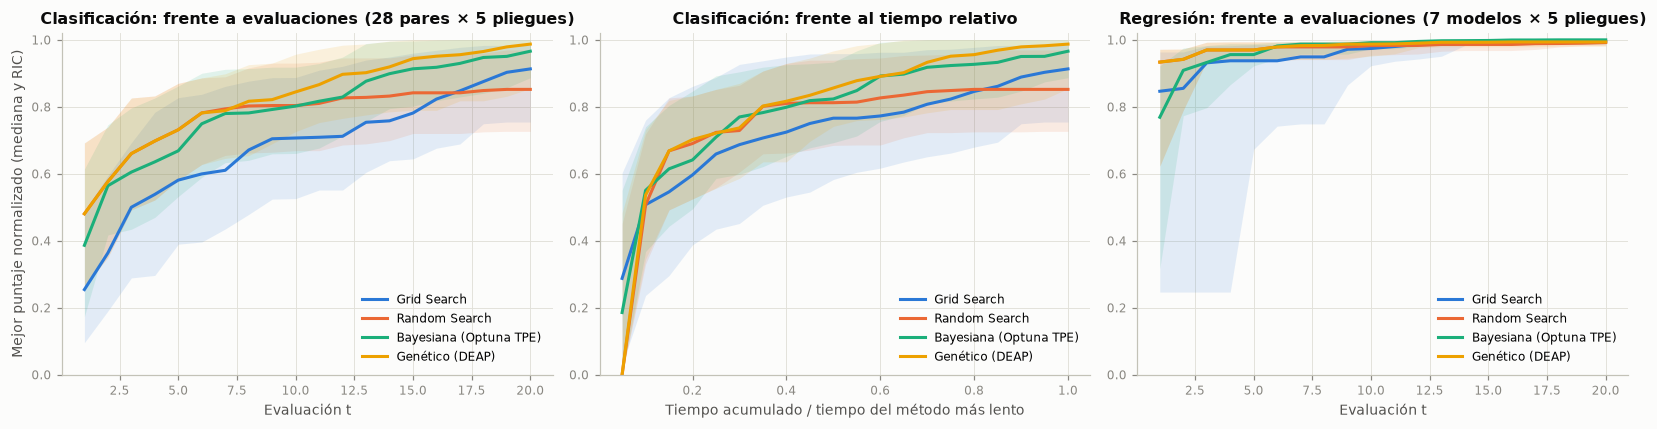

**Interpretación.** En la mediana de los bloques de clasificación, el puntaje normalizado llega a 0,9 en la evaluación 19 con Grid Search; nunca (en 20) con Random Search; 15 con Bayesiana (Optuna TPE); 13 con Genético (DEAP). Tras 5 evaluaciones, la mediana es de 0,58 (Grid Search), 0,73 (Random Search), 0,67 (Bayesiana (Optuna TPE)) y 0,73 (Genético (DEAP)); al final del presupuesto, de 0,91 (Grid Search), 0,85 (Random Search), 0,97 (Bayesiana (Optuna TPE)) y 0,99 (Genético (DEAP)).

Hay que tener en cuenta que las cinco primeras evaluaciones de Optuna son aleatorias, así que su curva solo puede separarse de la de Random Search a partir de la sexta; el genético tampoco puede mejorar antes de completar la población inicial de seis individuos. La forma de las curvas, más que su punto final, muestra cuánto presupuesto necesita cada método para llegar a una buena región.

De ahí que se opte por cuantificar esa diferencia con el área bajo la curva *anytime* y con las evaluaciones necesarias para llegar al 99 % del mejor valor (sección 5.5), y probarla estadísticamente.

In [46]:
T = cfg.PRESUPUESTO
h = historial.copy()
h["bloque"] = h["tarea"] + "|" + h["modelo"] + "|" + h["balanceo"] + "|" + h["pliegue"].astype(str)
finito = h[np.isfinite(h["puntaje"])]
ref = finito.groupby("bloque")["puntaje"].agg(ref_max="max", ref_min="min")
T_bloque = h.groupby(["bloque", "optimizador"])["t_acum"].max().groupby("bloque").max()
REJ_TAU = np.linspace(0.05, 1, 20)

curvas, curvas_t, eficiencia = {}, {}, []
for (b_, o_), g in h.groupby(["bloque", "optimizador"]):
    lo, hi = ref.loc[b_, "ref_min"], ref.loc[b_, "ref_max"]
    rango = hi - lo if hi > lo else 1.0
    mejor = g.set_index("n")["mejor"].reindex(range(1, T + 1)).ffill().replace(-np.inf, np.nan).fillna(lo)
    norm = ((mejor - lo) / rango).clip(0, 1).to_numpy()
    curvas[(b_, o_)] = norm
    tt = g["t_acum"].to_numpy() / T_bloque.loc[b_]
    mt = np.array([g["mejor"][tt <= tau].max() if (tt <= tau).any() else lo for tau in REJ_TAU])
    curvas_t[(b_, o_)] = np.clip((np.where(np.isfinite(mt), mt, lo) - lo) / rango, 0, 1)
    tarea_ = b_.split("|")[0]
    alcanza = (mejor >= 0.99 * hi) if tarea_ == "clf" else (-mejor <= 1.01 * -hi)
    eficiencia.append({"bloque": b_, "tarea": tarea_, "modelo": b_.split("|")[1], "optimizador": o_,
                       "AUAC evaluaciones": norm.mean(), "AUAC tiempo": curvas_t[(b_, o_)].mean(),
                       "Final normalizado": norm[-1],
                       "Evaluaciones al 99 %": int(np.argmax(alcanza.to_numpy())) + 1 if alcanza.any() else np.nan,
                       "Tiempo total (s)": g["t_acum"].max()})
eficiencia = pd.DataFrame(eficiencia)


def banda(ax, claves, x, opt, matriz):
    M = np.vstack([matriz[c] for c in claves])
    ax.plot(x, np.median(M, axis=0), color=COLOR_OPT[opt], label=NO[opt])
    ax.fill_between(x, np.quantile(M, 0.25, axis=0), np.quantile(M, 0.75, axis=0), color=COLOR_OPT[opt], alpha=0.12,
                    lw=0)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
bloques_clf = [b_ for b_ in ref.index if b_.startswith("clf")]
bloques_reg = [b_ for b_ in ref.index if b_.startswith("reg")]
for o_ in NUCLEO:
    banda(axs[0], [(b_, o_) for b_ in bloques_clf], np.arange(1, T + 1), o_, curvas)
    banda(axs[1], [(b_, o_) for b_ in bloques_clf], REJ_TAU, o_, curvas_t)
    banda(axs[2], [(b_, o_) for b_ in bloques_reg], np.arange(1, T + 1), o_, curvas)
axs[0].set(title="Clasificación: frente a evaluaciones (28 pares × 5 pliegues)", xlabel="Evaluación t",
           ylabel="Mejor puntaje normalizado (mediana y RIC)")
axs[1].set(title="Clasificación: frente al tiempo relativo", xlabel="Tiempo acumulado / tiempo del método más lento")
axs[2].set(title="Regresión: frente a evaluaciones (7 modelos × 5 pliegues)", xlabel="Evaluación t")
for ax in axs:
    ax.set_ylim(0, 1.02)
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

med = {o_: np.median(np.vstack([curvas[(b_, o_)] for b_ in bloques_clf]), axis=0) for o_ in NUCLEO}
t90 = {o_: (int(np.argmax(med[o_] >= 0.9)) + 1 if (med[o_] >= 0.9).any() else None) for o_ in NUCLEO}
interpretar(
    "En la mediana de los bloques de clasificación, el puntaje normalizado llega a 0,9 en la evaluación "
    + "; ".join(f"{t90[o_] if t90[o_] else 'nunca (en 20)'} con {NO[o_]}" for o_ in NUCLEO)
    + f". Tras 5 evaluaciones, la mediana es de {enumerar([num(med[o_][4], 2) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}; "
    f"al final del presupuesto, de {enumerar([num(med[o_][-1], 2) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}.",
    conectar("Hay que tener en cuenta que", "Las cinco primeras evaluaciones de Optuna son aleatorias, así que su curva "
             "solo puede separarse de la de Random Search a partir de la sexta; el genético tampoco puede mejorar antes "
             "de completar la población inicial de seis individuos. La forma de las curvas, más que su punto final, "
             "muestra cuánto presupuesto necesita cada método para llegar a una buena región."),
    conectar("De ahí que se opte por", "Cuantificar esa diferencia con el área bajo la curva *anytime* y con las "
             "evaluaciones necesarias para llegar al 99 % del mejor valor (sección 5.5), y probarla estadísticamente."))

filas_any = []
for t_, bloques_t in (("clf", bloques_clf), ("reg", bloques_reg)):
    for o_ in NUCLEO:
        for eje, x, mat in (("evaluaciones", np.arange(1, T + 1), curvas), ("tiempo", REJ_TAU, curvas_t)):
            M = np.vstack([mat[(b_, o_)] for b_ in bloques_t])
            for xi, me, q1, q3 in zip(x, np.median(M, 0), np.quantile(M, .25, 0), np.quantile(M, .75, 0)):
                filas_any.append({"grupo": t_, "optimizador": NO[o_], "eje": eje, "x": float(xi), "mediana": me,
                                  "q1": q1, "q3": q3})
exportar("anytime", pd.DataFrame(filas_any))


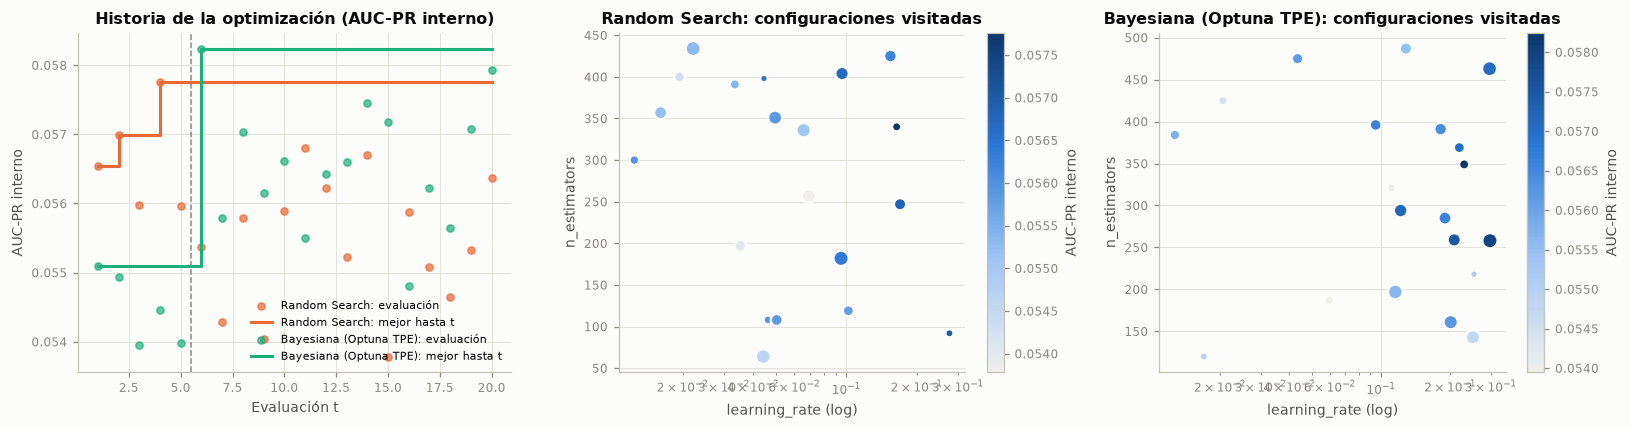

El tamaño del punto crece con el orden de la evaluación; la línea discontinua marca el fin de la fase aleatoria de TPE.


In [47]:
# Historia de Optuna y regiones visitadas: XGBoost sin balanceo, último pliegue externo
b_ej = "clf|xgboost|ninguno|4"
ej = h[h["bloque"] == b_ej]
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for o_ in ["random", "bayes"]:
    g = ej[ej["optimizador"] == o_]
    axs[0].scatter(g["n"], g["puntaje"], s=22, color=COLOR_OPT[o_], alpha=0.7, label=f"{NO[o_]}: evaluación")
    axs[0].step(g["n"], g["mejor"], where="post", color=COLOR_OPT[o_], lw=2, label=f"{NO[o_]}: mejor hasta t")
axs[0].axvline(5.5, color=GRIS, lw=1, ls="--")
axs[0].set(title="Historia de la optimización (AUC-PR interno)", xlabel="Evaluación t", ylabel="AUC-PR interno")
axs[0].legend(fontsize=7)
for ax, o_ in zip(axs[1:], ["random", "bayes"]):
    g = ej[ej["optimizador"] == o_]
    pr = pd.DataFrame([json.loads(p_) for p_ in g["params"]])
    sc = ax.scatter(pr["modelo__learning_rate"], pr["modelo__n_estimators"], c=g["puntaje"].to_numpy(), cmap=CMAP_SEQ,
                    s=20 + 4 * g["n"].to_numpy(), edgecolor=FONDO, lw=1.5)
    ax.set_xscale("log")
    ax.set(title=f"{NO[o_]}: configuraciones visitadas", xlabel="learning_rate (log)", ylabel="n_estimators")
    fig.colorbar(sc, ax=ax, label="AUC-PR interno")
plt.tight_layout()
plt.show()
print("El tamaño del punto crece con el orden de la evaluación; la línea discontinua marca el fin de la fase aleatoria de TPE.")

exportar("optuna_ejemplo", ej[["optimizador", "n", "puntaje", "mejor", "params"]].assign(optimizador=lambda d: d["optimizador"].map(NO)))


## 5.5 Eficiencia: calidad por unidad de presupuesto

La guía pide demostrar con evidencia cuantitativa, y no solo visual, si los métodos bayesiano y genético son más eficientes que Grid y Random Search. Para cada bloque y método se calculan tres indicadores: el **área bajo la curva *anytime*** frente a evaluaciones y frente al tiempo (promedio del puntaje normalizado; 1 = llegar al mejor valor desde la primera evaluación), y las **evaluaciones necesarias para alcanzar el 99 % del mejor valor** del bloque. Las diferencias se prueban con Friedman sobre los bloques, con comparaciones de Wilcoxon por pares ajustadas por Holm y con el delta de Cliff como tamaño de efecto.

In [48]:
from scipy.stats import wilcoxon

ef = eficiencia[eficiencia["optimizador"].isin(NUCLEO)]
for tarea_, nombre in (("clf", "Clasificación"), ("reg", "Regresión")):
    e_ = ef[ef["tarea"] == tarea_]
    res = e_.groupby("optimizador").agg(**{
        "AUAC evaluaciones": ("AUAC evaluaciones", "mean"), "AUAC tiempo": ("AUAC tiempo", "mean"),
        "Final normalizado": ("Final normalizado", "mean"),
        "% de bloques que llega al 99 %": ("Evaluaciones al 99 %", lambda s: 100 * s.notna().mean()),
        "Evaluaciones al 99 % (mediana)": ("Evaluaciones al 99 %", "median")}).loc[NUCLEO]
    res.index = [NO[o] for o in res.index]
    print(nombre)
    tabla(res, dec=3)

e_clf = ef[ef["tarea"] == "clf"]
mat_auac = e_clf.pivot(index="bloque", columns="optimizador", values="AUAC evaluaciones")[NUCLEO]
mat_auac_t = e_clf.pivot(index="bloque", columns="optimizador", values="AUAC tiempo")[NUCLEO]
fr_auac, fr_auac_t = st.friedman(mat_auac), st.friedman(mat_auac_t)
pares = [("bayes", "grid"), ("bayes", "random"), ("genetico", "grid"), ("genetico", "random"), ("bayes", "genetico"),
         ("random", "grid")]
filas = []
for a_, b2 in pares:
    for nombre, M in (("evaluaciones", mat_auac), ("tiempo", mat_auac_t)):
        w = wilcoxon(M[a_], M[b2])
        filas.append({"Comparación": f"{NO[a_]} vs {NO[b2]}", "AUAC frente a": nombre,
                      "Diferencia media": (M[a_] - M[b2]).mean(), "p crudo": w.pvalue,
                      "delta de Cliff": st.delta_cliff(M[a_], M[b2])})
comp_ef = pd.DataFrame(filas)
comp_ef["p Holm"] = np.nan
for nombre in ("evaluaciones", "tiempo"):
    m_ = comp_ef["AUAC frente a"] == nombre
    comp_ef.loc[m_, "p Holm"] = st.ajustar_p(comp_ef.loc[m_, "p crudo"], "holm")
comp_ef["Magnitud"] = comp_ef["delta de Cliff"].apply(st.magnitud_cliff)
print(f"Friedman sobre el AUAC (clasificación, {fr_auac['n_bloques']} bloques): frente a evaluaciones "
      f"χ² = {num(fr_auac['chi2'], 2)}, {p_txt(fr_auac['p'])}; frente al tiempo χ² = {num(fr_auac_t['chi2'], 2)}, "
      f"{p_txt(fr_auac_t['p'])}")
tabla(comp_ef.assign(**{"p crudo": comp_ef["p crudo"].map(pval), "p Holm": comp_ef["p Holm"].map(pval)}), dec=3,
      indice=False)

auac_m = mat_auac.mean()
sig = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & (comp_ef["p Holm"] < 0.05)]
b_vs = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & comp_ef["Comparación"].str.startswith(NO["bayes"])]
g_vs = comp_ef[(comp_ef["AUAC frente a"] == "evaluaciones") & comp_ef["Comparación"].str.startswith(NO["genetico"])]
interpretar(
    f"El área bajo la curva *anytime* frente a evaluaciones es de "
    f"{enumerar([num(auac_m[o_], 3) + ' (' + NO[o_] + ')' for o_ in NUCLEO], codigo=False)}; Friedman da "
    f"{p_txt(fr_auac['p'])} frente a evaluaciones y {p_txt(fr_auac_t['p'])} frente al tiempo. Frente a Grid y Random "
    f"Search, el delta de Cliff de la optimización bayesiana es de "
    f"{enumerar([num(d_, 2) for d_ in b_vs['delta de Cliff'].iloc[:2]], codigo=False)} y el del genético de "
    f"{enumerar([num(d_, 2) for d_ in g_vs['delta de Cliff'].iloc[:2]], codigo=False)}; "
    f"{len(sig)} de las {len(pares)} comparaciones por pares son significativas tras el ajuste de Holm.",
    conectar("Esto quiere decir que", (
        f"Frente a Grid Search la ventaja de los métodos adaptativos es clara (efecto {st.magnitud_cliff(b_vs['delta de Cliff'].iloc[0])} "
        f"en la bayesiana y {st.magnitud_cliff(g_vs['delta de Cliff'].iloc[0])} en el genético, según el delta de Cliff): la "
        "rejilla gasta las primeras evaluaciones en combinaciones fijas, a menudo en regiones malas, mientras que los "
        "métodos adaptativos usan las evaluaciones anteriores para concentrar el presupuesto. "
        if (b_vs["Diferencia media"].iloc[0] > 0 and g_vs["Diferencia media"].iloc[0] > 0) else
        "Frente a Grid Search no hay una ventaja uniforme de los métodos adaptativos. ")
        + (f"Frente a Random Search, en cambio, el efecto es {st.magnitud_cliff(b_vs['delta de Cliff'].iloc[1])} en la "
           f"bayesiana y {st.magnitud_cliff(g_vs['delta de Cliff'].iloc[1])} en el genético: la fase inicial aleatoria (5 "
           "evaluaciones en Optuna, 6 en el genético) consume una parte grande de un presupuesto de 20, y en espacios de "
           "dos a cuatro dimensiones el muestreo aleatorio ya cubre bien las regiones relevantes. La magnitud del efecto, "
           "y no solo el valor p, es la que indica si la diferencia importa en la práctica.")),
    conectar("Así las cosas, se decide", "Interpretar la eficiencia como un resultado condicionado al presupuesto y a la "
             "dimensión del espacio: con espacios de mayor dimensión o presupuestos mayores, la teoría y la literatura "
             "predicen que la ventaja de TPE crece (Bergstra et al., 2011), algo que este diseño no alcanza a medir."))

exportar("eficiencia", pd.concat([ef[ef["tarea"] == t_].groupby("optimizador")[["AUAC evaluaciones", "AUAC tiempo",
         "Final normalizado"]].mean().assign(tarea=t_).rename(index=NO) for t_ in ("clf", "reg")]).reset_index())
exportar("eficiencia_pruebas", comp_ef)


Clasificación


,AUAC evaluaciones,AUAC tiempo,Final normalizado,% de bloques que llega al 99 %,Evaluaciones al 99 % (mediana)
Grid Search,"0,670","0,706","0,847","52,143","12,000"
Random Search,"0,753","0,741","0,830","41,429","5,500"
Bayesiana (Optuna TPE),"0,773","0,777","0,920","66,429","11,000"
Genético (DEAP),"0,781","0,768","0,895","68,571","9,000"


Regresión


,AUAC evaluaciones,AUAC tiempo,Final normalizado,% de bloques que llega al 99 %,Evaluaciones al 99 % (mediana)
Grid Search,"0,842","0,830","0,990","97,143","1,000"
Random Search,"0,949","0,931","0,982","97,143","1,000"
Bayesiana (Optuna TPE),"0,943","0,926","0,993","100,000","1,000"
Genético (DEAP),"0,954","0,940","0,986","100,000","1,000"


Friedman sobre el AUAC (clasificación, 140 bloques): frente a evaluaciones χ² = 43,99, p < 0,001; frente al tiempo χ² = 23,94, p < 0,001


Comparación,AUAC frente a,Diferencia media,p crudo,delta de Cliff,p Holm,Magnitud
Bayesiana (Optuna TPE) vs Grid Search,evaluaciones,"0,103","< 0,001","0,329","< 0,001",pequeño
Bayesiana (Optuna TPE) vs Grid Search,tiempo,"0,071","< 0,001","0,186","< 0,001",pequeño
Bayesiana (Optuna TPE) vs Random Search,evaluaciones,"0,020","0,130","0,043","0,261",despreciable
Bayesiana (Optuna TPE) vs Random Search,tiempo,"0,036","0,013","0,124","0,038",despreciable
Genético (DEAP) vs Grid Search,evaluaciones,"0,112","< 0,001","0,338","< 0,001",mediano
Genético (DEAP) vs Grid Search,tiempo,"0,061","0,008","0,158","0,031",pequeño
Genético (DEAP) vs Random Search,evaluaciones,"0,028","< 0,001","0,127","< 0,001",despreciable
Genético (DEAP) vs Random Search,tiempo,"0,027","< 0,001","0,129","0,002",despreciable
Bayesiana (Optuna TPE) vs Genético (DEAP),evaluaciones,"-0,008","0,662","-0,104","0,662",despreciable
Bayesiana (Optuna TPE) vs Genético (DEAP),tiempo,"0,009","0,628","-0,031","0,628",despreciable


**Interpretación.** El área bajo la curva *anytime* frente a evaluaciones es de 0,670 (Grid Search), 0,753 (Random Search), 0,773 (Bayesiana (Optuna TPE)) y 0,781 (Genético (DEAP)); Friedman da p < 0,001 frente a evaluaciones y p < 0,001 frente al tiempo. Frente a Grid y Random Search, el delta de Cliff de la optimización bayesiana es de 0,33 y 0,04 y el del genético de 0,34 y 0,13; 4 de las 6 comparaciones por pares son significativas tras el ajuste de Holm.

Esto quiere decir que frente a Grid Search la ventaja de los métodos adaptativos es clara (efecto pequeño en la bayesiana y mediano en el genético, según el delta de Cliff): la rejilla gasta las primeras evaluaciones en combinaciones fijas, a menudo en regiones malas, mientras que los métodos adaptativos usan las evaluaciones anteriores para concentrar el presupuesto. Frente a Random Search, en cambio, el efecto es despreciable en la bayesiana y despreciable en el genético: la fase inicial aleatoria (5 evaluaciones en Optuna, 6 en el genético) consume una parte grande de un presupuesto de 20, y en espacios de dos a cuatro dimensiones el muestreo aleatorio ya cubre bien las regiones relevantes. La magnitud del efecto, y no solo el valor p, es la que indica si la diferencia importa en la práctica.

Así las cosas, se decide interpretar la eficiencia como un resultado condicionado al presupuesto y a la dimensión del espacio: con espacios de mayor dimensión o presupuestos mayores, la teoría y la literatura predicen que la ventaja de TPE crece (Bergstra et al., 2011), algo que este diseño no alcanza a medir.

## 5.6 Algoritmo genético: diversidad y convergencia prematura

Una población que pierde diversidad antes de encontrar buenas soluciones converge de forma prematura: el cruce entre individuos casi iguales ya no explora. La diversidad se mide como la distancia euclídea media entre los genes de los individuos, normalizada por √d, en cada generación de todas las corridas del genético.

,Corridas,Diversidad (mediana),Q1,Q3,"% con diversidad < 0,1",Evaluaciones acumuladas (mediana)
generacion,,,,,,
0,175,"0,388","0,386","0,411","0,000","6,000"
1,175,"0,236","0,139","0,315","9,143","10,000"
2,175,"0,098","0,022","0,186","51,429","10,000"
3,175,"0,017","0,003","0,060","79,429","11,000"
4,175,"0,038","0,004","0,049","90,286","12,000"
5,174,"0,018","0,006","0,038","96,552","13,000"
6,168,"0,018","0,004","0,035","99,405","14,000"
7,142,"0,014","0,004","0,022","99,296","15,000"
8,133,"0,021","0,011","0,034","100,000","16,000"


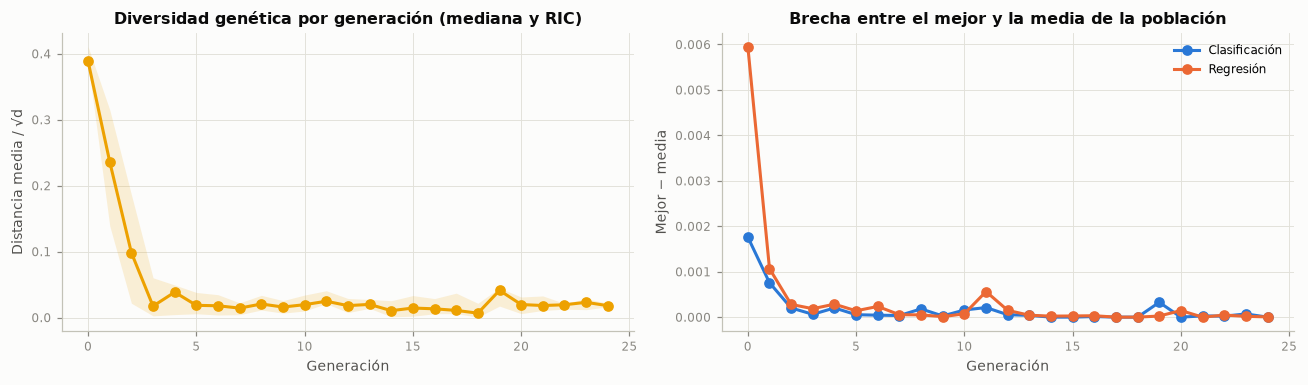

**Interpretación.** La diversidad mediana pasa de 0,388 en la población inicial a 0,018 en la generación 24 (una caída del 95 %), y el porcentaje de corridas con diversidad menor que 0,1 sube del 0,0 % al 100,0 %. La población inicial de un genoma uniforme tiene una diversidad esperada cercana a 0,41. Cada corrida usó una mediana de 11 generaciones (entre 4 y 50).

Lo anterior indica que la población se concentra rápido, como se espera con elitismo y torneo de tamaño 3: el genético pasa casi de inmediato a explotar la región del mejor individuo y, cuando la población converge, las generaciones siguientes producen sobre todo clones ya evaluados (por eso hay corridas con muchas generaciones y pocas evaluaciones nuevas). Es una señal de convergencia prematura, con riesgo de quedarse en un óptimo local.

Por esta razón, lo indicado es leer el buen desempeño del genético en las curvas *anytime* (sección 5.5) como el de una búsqueda que explota pronto una región buena, no como una exploración completa del espacio. Con más presupuesto convendría una población mayor, una mutación adaptativa que reinyecte diversidad cuando caiga por debajo de un umbral o reemplazar los clones por individuos aleatorios.

In [49]:
gen = pd.DataFrame([{**{k: c[k] for k in ("tarea", "modelo", "balanceo", "pliegue")}, **g_}
                    for c in corridas if c["optimizador"] == "genetico" and c["seed"] == SEED
                    for g_ in c["info"]["generaciones"]])
div = gen.groupby("generacion").agg(corridas=("diversidad", "size"), diversidad_mediana=("diversidad", "median"),
                                    q25=("diversidad", lambda s: s.quantile(0.25)),
                                    q75=("diversidad", lambda s: s.quantile(0.75)),
                                    pct_baja=("diversidad", lambda s: 100 * (s < 0.1).mean()),
                                    n_eval=("n_eval", "median"))
div = div[div["corridas"] >= 10]
tabla(div.rename(columns={"corridas": "Corridas", "diversidad_mediana": "Diversidad (mediana)", "q25": "Q1", "q75": "Q3",
                          "pct_baja": "% con diversidad < 0,1", "n_eval": "Evaluaciones acumuladas (mediana)"}), dec=3)

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].plot(div.index, div["diversidad_mediana"], color=CAT[3], marker="o")
axs[0].fill_between(div.index, div["q25"], div["q75"], color=CAT[3], alpha=0.15, lw=0)
axs[0].set(title="Diversidad genética por generación (mediana y RIC)", xlabel="Generación",
           ylabel="Distancia media / √d")
gen["brecha"] = gen["mejor"] - gen["media"]
br = gen[gen["generacion"].isin(div.index)].groupby(["tarea", "generacion"])["brecha"].median().unstack(0)
for t_, col in zip(br.columns, [AZUL, NARANJA]):
    axs[1].plot(br.index, br[t_], marker="o", color=col, label="Clasificación" if t_ == "clf" else "Regresión")
axs[1].set(title="Brecha entre el mejor y la media de la población", xlabel="Generación", ylabel="Mejor − media")
axs[1].legend()
plt.tight_layout()
plt.show()

d0, dU = div["diversidad_mediana"].iloc[0], div["diversidad_mediana"].iloc[-1]
n_gen = gen.groupby(["tarea", "modelo", "balanceo", "pliegue"])["generacion"].max()
interpretar(
    f"La diversidad mediana pasa de {num(d0, 3)} en la población inicial a {num(dU, 3)} en la generación "
    f"{div.index[-1]} (una caída del {pct(1 - dU / d0, 0)}), y el porcentaje de corridas con diversidad menor que 0,1 "
    f"sube del {num(div['pct_baja'].iloc[0], 1)} % al {num(div['pct_baja'].iloc[-1], 1)} %. La población inicial de "
    f"un genoma uniforme tiene una diversidad esperada cercana a 0,41. Cada corrida usó una mediana de "
    f"{num(n_gen.median())} generaciones (entre {num(n_gen.min())} y {num(n_gen.max())}).",
    conectar("Lo anterior indica que", ("La población se concentra rápido, como se espera con elitismo y torneo de "
             "tamaño 3: el genético pasa casi de inmediato a explotar la región del mejor individuo y, cuando la "
             "población converge, las generaciones siguientes producen sobre todo clones ya evaluados (por eso hay "
             "corridas con muchas generaciones y pocas evaluaciones nuevas). Es una señal de convergencia prematura, "
             "con riesgo de quedarse en un óptimo local."
             if dU / d0 < 0.5 else "La población conserva buena parte de su diversidad en las pocas generaciones que "
             "permite el presupuesto, así que el genético sigue explorando y no hay señales de convergencia prematura; "
             "el costo es que tampoco alcanza a explotar a fondo la mejor región.")),
    conectar("Por esta razón, lo indicado es", "Leer el buen desempeño del genético en las curvas *anytime* (sección "
             "5.5) como el de una búsqueda que explota pronto una región buena, no como una exploración completa del "
             "espacio. Con más presupuesto convendría una población mayor, una mutación adaptativa que reinyecte "
             "diversidad cuando caiga por debajo de un umbral o reemplazar los clones por individuos aleatorios."))

exportar("genetico_diversidad", div.reset_index())


## 5.7 Multi-fidelidad: Successive Halving

Successive Halving se compara con Random Search y con Optuna en las mismas combinaciones (Random Forest y XGBoost sin balanceo) y en los mismos pliegues externos. Su costo se expresa en **evaluaciones equivalentes**: suma de árboles entrenados en todas las configuraciones dividida por el número máximo de árboles.

In [50]:
hv = pd.DataFrame([{k: c[k] for k in ("modelo", "pliegue", "auc_pr", "auc", "t_opt", "n_eval", "eval_equivalentes")}
                   for c in corridas if c["optimizador"] == "halving"])
ref_hv = pliegues[(pliegues["tarea"] == "clf") & (pliegues["balanceo"] == "ninguno") &
                  pliegues["modelo"].isin(["bosque", "xgboost"]) & pliegues["optimizador"].isin(["random", "bayes"])]
filas = []
for m_ in ("bosque", "xgboost"):
    for o_, d_ in [("halving", hv[hv["modelo"] == m_])] + [(o_, ref_hv[(ref_hv["modelo"] == m_) &
                                                                       (ref_hv["optimizador"] == o_)])
                                                           for o_ in ("random", "bayes")]:
        filas.append({"Modelo": NM[m_], "Método": NO[o_], "AUC-PR externo": ms(d_["auc_pr"]),
                      "AUC externo": ms(d_["auc"]), "Configuraciones evaluadas por pliegue": d_["n_eval"].mean(),
                      "Evaluaciones equivalentes por pliegue": d_["eval_equivalentes"].mean() if o_ == "halving"
                      else d_["n_eval"].mean(), "Tiempo por pliegue (s)": d_["t_opt"].mean()})
tabla(pd.DataFrame(filas), dec=1, indice=False)

rondas_hv = pd.DataFrame([{**r_, "modelo": c["modelo"]} for c in corridas if c["optimizador"] == "halving"
                          for r_ in c["rondas"]])
tabla(rondas_hv.groupby(["modelo", "iter"]).agg(Candidatos=("candidatos", "first"), Árboles=("arboles", "first"),
                                                **{"Mejor AUC-PR interno (media)": ("mejor", "mean")}), dec=4)

t_hv = hv.groupby("modelo")["t_opt"].mean()
t_rs = ref_hv[ref_hv["optimizador"] == "random"].groupby("modelo")["t_opt"].mean()
ap_hv = hv.groupby("modelo")["auc_pr"].mean()
ap_rs = ref_hv[ref_hv["optimizador"] == "random"].groupby("modelo")["auc_pr"].mean()
interpretar(
    f"Successive Halving evalúa {int(hv['n_eval'].mean())} configuraciones por pliegue con un costo equivalente a "
    f"{num(hv['eval_equivalentes'].mean(), 1)} evaluaciones completas, frente a las 20 de Random Search. Su tiempo por "
    f"pliegue es {num(t_hv['xgboost'], 0)} s en XGBoost y {num(t_hv['bosque'], 0)} s en Random Forest, frente a "
    f"{num(t_rs['xgboost'], 0)} s y {num(t_rs['bosque'], 0)} s de Random Search; el AUC-PR externo cambia en "
    f"{num(ap_hv['xgboost'] - ap_rs['xgboost'], 3)} y {num(ap_hv['bosque'] - ap_rs['bosque'], 3)}, respectivamente.",
    "Es decir, con " + pct(hv["eval_equivalentes"].mean() / cfg.PRESUPUESTO, 0) + " de las evaluaciones "
    "equivalentes de Random Search, la eliminación sucesiva examina el doble de configuraciones porque descarta "
    "temprano las que rinden mal con pocos árboles. El ahorro de tiempo (" + pct(1 - t_hv["xgboost"] / t_rs["xgboost"], 0)
    + " en XGBoost y " + pct(1 - t_hv["bosque"] / t_rs["bosque"], 0) + " en Random Forest) es menor que el de árboles, "
    "porque cada evaluación tiene costos que no dependen del número de árboles (preprocesamiento y tres pliegues "
    "internos). La condición para que funcione es que el orden de las configuraciones con pocos árboles se parezca al "
    "orden con muchos; la tabla de rondas muestra si el mejor puntaje sube o baja al aumentar la fidelidad.",
    conectar("Por ello, se recomienda", "Usar la multi-fidelidad cuando el costo por evaluación domina (bosques y "
             "*boosting* con muchos árboles) y reasignar el presupuesto ahorrado a más configuraciones, tal como pide la "
             "guía; en modelos baratos como Naive Bayes o la logística la ganancia no compensa la complejidad."))

exportar("halving", pd.DataFrame(filas))


Modelo,Método,AUC-PR externo,AUC externo,Configuraciones evaluadas por pliegue,Evaluaciones equivalentes por pliegue,Tiempo por pliegue (s)
Random Forest,Successive Halving,"0,092 ± 0,086","0,534 ± 0,086","39,0","8,9","149,3"
Random Forest,Random Search,"0,088 ± 0,078","0,523 ± 0,081","20,0","20,0","207,3"
Random Forest,Bayesiana (Optuna TPE),"0,095 ± 0,092","0,538 ± 0,079","20,0","20,0","282,3"
XGBoost,Successive Halving,"0,087 ± 0,073","0,528 ± 0,056","39,0","8,9","140,6"
XGBoost,Random Search,"0,088 ± 0,076","0,537 ± 0,065","20,0","20,0","163,3"
XGBoost,Bayesiana (Optuna TPE),"0,088 ± 0,078","0,529 ± 0,066","20,0","20,0","159,4"


**Interpretación.** Successive Halving evalúa 39 configuraciones por pliegue con un costo equivalente a 8,9 evaluaciones completas, frente a las 20 de Random Search. Su tiempo por pliegue es 141 s en XGBoost y 149 s en Random Forest, frente a 163 s y 207 s de Random Search; el AUC-PR externo cambia en -0,001 y 0,004, respectivamente.

Es decir, con 45 % de las evaluaciones equivalentes de Random Search, la eliminación sucesiva examina el doble de configuraciones porque descarta temprano las que rinden mal con pocos árboles. El ahorro de tiempo (14 % en XGBoost y 28 % en Random Forest) es menor que el de árboles, porque cada evaluación tiene costos que no dependen del número de árboles (preprocesamiento y tres pliegues internos). La condición para que funcione es que el orden de las configuraciones con pocos árboles se parezca al orden con muchos; la tabla de rondas muestra si el mejor puntaje sube o baja al aumentar la fidelidad.

Por ello, se recomienda usar la multi-fidelidad cuando el costo por evaluación domina (bosques y *boosting* con muchos árboles) y reasignar el presupuesto ahorrado a más configuraciones, tal como pide la guía; en modelos baratos como Naive Bayes o la logística la ganancia no compensa la complejidad.

## 5.8 Estabilidad de las soluciones ante distintas semillas

Los métodos estocásticos (Random Search, Optuna y el genético) se repiten con tres semillas adicionales (1, 2 y 3) en XGBoost sin balanceo, en los cinco pliegues externos. Grid Search es determinista dado el espacio, así que su variación por semilla del optimizador es nula.

In [51]:
sem = pd.DataFrame([{k: c[k] for k in ("optimizador", "pliegue", "seed", "auc_pr", "puntaje_interno")}
                    | {"lr": c["params"]["modelo__learning_rate"], "arboles": c["params"]["modelo__n_estimators"]}
                    for c in corridas if c["tarea"] == "clf" and c["modelo"] == "xgboost" and c["balanceo"] == "ninguno"
                    and c["optimizador"] in ("random", "bayes", "genetico")])
por_sem = sem.groupby(["optimizador", "seed"])["auc_pr"].mean().unstack()
estab = pd.DataFrame({
    "AUC-PR externo por semilla (media de 5 pliegues)": por_sem.apply(lambda r_: "; ".join(num(v, 4) for v in r_), axis=1),
    "Desv. est. entre semillas": por_sem.std(axis=1, ddof=1),
    "Desv. est. entre pliegues (semilla 42)": sem[sem["seed"] == SEED].groupby("optimizador")["auc_pr"].std(),
    "Desv. est. de log10(learning_rate) entre semillas (media por pliegue)":
        sem.assign(llr=np.log10(sem["lr"])).groupby(["optimizador", "pliegue"])["llr"].std().groupby("optimizador").mean(),
    "Desv. est. del puntaje interno entre semillas":
        sem.groupby(["optimizador", "pliegue"])["puntaje_interno"].std().groupby("optimizador").mean()})
estab.index = [NO[o] for o in estab.index]
tabla(estab, dec=4)

r_ = estab["Desv. est. entre semillas"] / estab["Desv. est. entre pliegues (semilla 42)"]
interpretar(
    f"La desviación del AUC-PR externo entre semillas es de "
    f"{enumerar([num(v, 4) + ' (' + i + ')' for i, v in estab['Desv. est. entre semillas'].items()], codigo=False)}, "
    f"entre {num(r_.min(), 2)} y {num(r_.max(), 2)} veces la desviación entre pliegues. La tasa de aprendizaje elegida "
    f"varía en promedio {enumerar([num(v, 2) for v in estab.iloc[:, 3]], codigo=False)} órdenes de magnitud (log10) "
    f"entre semillas.",
    conectar("Esto significa que", "Las soluciones de los métodos estocásticos no son únicas: semillas distintas llevan a "
             "hiperparámetros diferentes con desempeños parecidos, lo que indica una superficie de respuesta plana "
             "cerca del óptimo. " + ("La variación por semilla es pequeña frente a la que hay entre periodos, así que no "
             "cambia las conclusiones." if r_.max() < 0.5 else "La variación por semilla no es despreciable frente a la "
             "que hay entre periodos, así que una sola corrida puede ordenar mal dos métodos cercanos.")),
    conectar("Por tanto, corresponde", "Reportar los hiperparámetros elegidos como una de varias soluciones equivalentes y "
             "no sobreinterpretar su valor exacto; para la comparación entre métodos, la prueba por bloques de la "
             "sección 5.5 ya promedia esta fuente de variación."))

exportar("semillas_optimizador", estab.reset_index())


,AUC-PR externo por semilla (media de 5 pliegues),Desv. est. entre semillas,Desv. est. entre pliegues (semilla 42),Desv. est. de log10(learning_rate) entre semillas (media por pliegue),Desv. est. del puntaje interno entre semillas
Bayesiana (Optuna TPE),"0,0871; 0,0876; 0,0844; 0,0880","0,0017","0,0782","0,3458","0,0021"
Genético (DEAP),"0,0887; 0,0881; 0,0909; 0,0893","0,0012","0,0756","0,3027","0,0015"
Random Search,"0,0875; 0,0925; 0,0826; 0,0885","0,0041","0,0759","0,3693","0,0015"


**Interpretación.** La desviación del AUC-PR externo entre semillas es de 0,0017 (Bayesiana (Optuna TPE)), 0,0012 (Genético (DEAP)) y 0,0041 (Random Search), entre 0,02 y 0,05 veces la desviación entre pliegues. La tasa de aprendizaje elegida varía en promedio 0,35, 0,30 y 0,37 órdenes de magnitud (log10) entre semillas.

Esto significa que las soluciones de los métodos estocásticos no son únicas: semillas distintas llevan a hiperparámetros diferentes con desempeños parecidos, lo que indica una superficie de respuesta plana cerca del óptimo. La variación por semilla es pequeña frente a la que hay entre periodos, así que no cambia las conclusiones.

Por tanto, corresponde reportar los hiperparámetros elegidos como una de varias soluciones equivalentes y no sobreinterpretar su valor exacto; para la comparación entre métodos, la prueba por bloques de la sección 5.5 ya promedia esta fuente de variación.